# 05 — Regression: Next-week recorded sales

This notebook predicts next-week recorded article sales using information available at the end of the current week. It builds on the prepared data in notebook 02 and the regression EDA in notebook 03. Each row is an article-week with at least one current sale. Stock availability is unknown, so recorded sales are not necessarily total customer demand.

## Objectives

- Compare three simple baselines: current-week sales, the recent four-week mean, and the recent four-week median.
- Train Ridge, a decision tree, Random Forest, and three boosting variants with the same predictors and training sample.
- Compare MAE, RMSE, and supplementary R² on later validation weeks.
- Check global error, high-sales error, and underprediction for articles with more than 20 target-week sales.
- Select a provisional candidate without opening the final test set; systematic tuning belongs in notebook 07.

**Computational Scope of this experiment**. The original chronological train, validation, and test partitions remain unchanged. For this initial comparison, each trained model uses the same reproducible sample of 100,000 training rows. The three baselines do not require training. All methods are evaluated on the complete validation partition. The results therefore describe models trained on this sample, not on the full training partition. The test partition is not used in this notebook.


## 1. Reproducible setup and data contract

Load the complete publication selected by `CURRENT.json`, verify its SHA-256 checksum, and read only the columns needed for regression. Article IDs remain text for auditing and are not used as numeric predictors. The target is next-week **recorded sales**; the chronological split was defined in notebook 02.


In [1]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/data/process_data.py").is_file()
             and (p / "data/processed/CURRENT.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open fashion-demand-ml and run notebook 02 first.")
processed = ROOT / "data/processed"
pointer = json.loads((processed / "CURRENT.json").read_text(encoding="utf-8"))
run = (processed / pointer["run_dir"]).resolve()
if pointer.get("preview") or not run.is_relative_to(processed.resolve()):
    raise ValueError("CURRENT.json does not point to a valid complete publication.")
checksums = json.loads((run / "checksums.json").read_text(encoding="utf-8"))
csv_path = run / "article_week.csv.gz"
digest = hashlib.sha256()
with csv_path.open("rb") as source:
    for block in iter(lambda: source.read(1024 * 1024), b""):
        digest.update(block)
expected = checksums["article_week.csv.gz"]
if isinstance(expected, dict):
    expected = expected.get("sha256")
if digest.hexdigest() != expected:
    raise ValueError("The CSV does not match its published SHA-256 checksum.")

numeric = ["sales", "lag_1_sales", "lag_4_sales", "rolling_4w_sales_mean",
           "rolling_12w_sales_mean", "mean_price", "online_share", "iso_week"]
categorical = ["product_group_name", "garment_group_name", "index_group_name"]
history_lags = [f"lag_{week}_sales" for week in range(1, 4)]
recent_weeks = ["sales", *history_lags]  # Current week and the three before it.
# Extra lags are loaded only for the simple baselines; model predictors remain unchanged.
columns = list(dict.fromkeys(["article_id", "target_week", "split", "target_next_week_sales",
                              *numeric, *categorical, *history_lags]))
data = pd.read_csv(csv_path, usecols=columns, dtype={"article_id": "string"},
                   parse_dates=["target_week"])
assert data["target_next_week_sales"].notna().all()
assert set(data["split"]) == {"train", "validation", "test"}
print("Publication:", run.name)
print("Rows by split:")
print(data["split"].value_counts().to_string())


Publication: 20261027T145552-5a1ac59a
Rows by split:
split
train         1326434
test           289490
validation     271215


## 2. Chronological split and simple baselines

Notebook 02 already assigned earlier target weeks to training and later weeks to validation. Here, a **baseline** is a simple prediction rule used as a point of comparison. It is not a trained estimator and does not need to appear in the model list in section 3.

- **Repeat current-week sales:** use this week's sales as the prediction for next week.
- **Four-week recent mean:** use the average of the **current week and the three weeks before it**.
- **Four-week recent median:** use the middle value of those same four weeks. For 1, 2, 3 and 50 units, the mean is 14 and the median is 2.5. The median is less affected by the unusual 50.

We add the median to answer a specific question: **does a simple rule that resists occasional sales spikes outperform the mean or the trained models?** Both four-week rules use the latest four sales values known when we make the prediction. For example, at the end of week 5 they use weeks 2, 3, 4 and 5 to predict week 6. They never use sales from the week being predicted. MAE is the average prediction error in units per article-week; lower is better. RMSE penalizes large errors more heavily, and R² is supplementary. All methods are assessed on the same validation rows.


In [2]:
train = data.loc[data["split"].eq("train")].copy()
validation = data.loc[data["split"].eq("validation")].copy()
del data  # Release the full table; final-test outcomes are not inspected.
assert train["target_week"].max() < validation["target_week"].min()

SEED = 42
MAX_TRAIN_ROWS = 100_000
train_sample = train.sample(n=min(MAX_TRAIN_ROWS, len(train)), random_state=SEED)
print("Available training rows:", len(train))
print("Rows used to fit each model:", len(train_sample))
print("Full validation rows:", len(validation))
print("Validation weeks:", validation["target_week"].nunique())
print("Predictors:", numeric + categorical)

def scores(y, prediction):
    return {"MAE": mean_absolute_error(y, prediction),
            "RMSE": np.sqrt(mean_squared_error(y, prediction)),
            "R2": r2_score(y, prediction)}

truth = validation["target_next_week_sales"].to_numpy()
predictions = {
    "Repeat current-week sales": validation["sales"].to_numpy(dtype=float),
    "Four-week recent mean": validation[recent_weeks].to_numpy(dtype=float).mean(axis=1),
    "Four-week recent median": np.median(validation[recent_weeks].to_numpy(dtype=float), axis=1),
}
print("Three baselines ready: current-week sales, recent four-week mean, and recent four-week median.")


Available training rows: 1326434
Rows used to fit each model: 100000
Full validation rows: 271215
Validation weeks: 15
Predictors: ['sales', 'lag_1_sales', 'lag_4_sales', 'rolling_4w_sales_mean', 'rolling_12w_sales_mean', 'mean_price', 'online_share', 'iso_week', 'product_group_name', 'garment_group_name', 'index_group_name']
Three baselines ready: current-week sales, recent four-week mean, and recent four-week median.


### Baselines ready for comparison

The three baselines now produce a next-week sales prediction for every validation row. They all use information available by the end of the current week:

- **Repeat current-week sales:** use the current week's sales.
- **Four-week recent mean:** average the current week and the previous three weeks.
- **Four-week recent median:** take the median of those same four values.

The mean and median use identical weeks; only the way they combine the four values differs. These are simple prediction rules, not trained models. Section 4 calculates their errors against the actual next-week sales and compares them with the trained models.

## 3. Preprocessing and candidate models

Missing numeric values are filled with each predictor's median calculated on training data; missing categories use the training mode. This missing-value step is separate from the four-week median baseline in section 2. Text categories are one-hot encoded and numeric predictors are scaled. A scikit-learn `Pipeline` learns these operations from the training sample only, then applies them to validation. IDs, dates, split labels, and future outcomes are excluded. The extra lag columns loaded for the recent baselines are **not** added to model predictors, preserving the original model comparison.

We compare Ridge, a decision tree, Random Forest, and three versions of the same histogram-based Gradient Boosting model. **Squared-error loss** emphasizes large misses. **Absolute-error loss** is closer to our main metric, MAE. **Poisson loss** is designed for nonnegative targets such as counts of sold units. The three Boosting versions use the same rows, predictors, and hyperparameters; only the training loss differs. They are all evaluated with the same MAE, RMSE, and R² on the same validation set. Section 5 also checks high-selling articles, because a lower global MAE can hide worse errors there. Systematic tuning belongs in notebook 07.

Negative sales predictions are counted and clipped to zero before scoring; the same policy applies to every model.


In [3]:
preprocess = ColumnTransformer([
    ("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric),
    ("categorical", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categorical),
], sparse_threshold=0)

assert (train_sample["target_next_week_sales"] >= 0).all()  # Required by Poisson loss.

estimators = {
    "Ridge": Ridge(alpha=10.0),
    "Decision tree": DecisionTreeRegressor(max_depth=12, min_samples_leaf=30, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=40, max_depth=14,
                                           min_samples_leaf=20, n_jobs=-1, random_state=SEED),
    "Boosting (squared error)": HistGradientBoostingRegressor(
        loss="squared_error", max_iter=100, max_leaf_nodes=31,
        learning_rate=0.08, random_state=SEED),
    "Boosting (absolute error)": HistGradientBoostingRegressor(
        loss="absolute_error", max_iter=100, max_leaf_nodes=31,
        learning_rate=0.08, random_state=SEED),
    "Boosting (Poisson)": HistGradientBoostingRegressor(
        loss="poisson", max_iter=100, max_leaf_nodes=31,
        learning_rate=0.08, random_state=SEED),
}
models = {}
negative_counts = {}
for name, estimator in estimators.items():
    model = Pipeline([("prepare", preprocess), ("model", estimator)])
    model.fit(train_sample[numeric + categorical], train_sample["target_next_week_sales"])
    raw_prediction = model.predict(validation[numeric + categorical])
    negative_counts[name] = int((raw_prediction < 0).sum())
    predictions[name] = np.clip(raw_prediction, 0, None)
    models[name] = model
    print(f"{name}: MAE={mean_absolute_error(truth, predictions[name]):.3f}; "
          f"negative predictions before clipping={negative_counts[name]:,}")


Ridge: MAE=8.183; negative predictions before clipping=8,215
Decision tree: MAE=7.843; negative predictions before clipping=0
Random Forest: MAE=7.580; negative predictions before clipping=0
Boosting (squared error): MAE=7.584; negative predictions before clipping=5
Boosting (absolute error): MAE=7.280; negative predictions before clipping=932
Boosting (Poisson): MAE=7.477; negative predictions before clipping=0


## 4. Model comparison on validation data

The first table is the main result: one row per baseline or model, sorted by MAE. Every score uses the **full validation set**. Values are shown to three decimal places so close results are distinguishable. The highlighted row has the lowest MAE; it is a provisional candidate, not a final winner.

The second table divides validation into three consecutive blocks of whole weeks. It shows whether a good overall average hides a difficult period. These blocks describe variation in the fixed validation period; the nested chronological validation required for parameter selection is developed in notebook 07.


In [4]:
from html import escape
from IPython.display import HTML, display

weeks = np.sort(validation["target_week"].unique())
windows = np.array_split(weeks, 3)
rows = []
for name, prediction in predictions.items():
    rows.append({"model_name": name, "window": "full", "rows": len(validation),
                 **scores(truth, prediction)})
    for i, block in enumerate(windows, start=1):
        mask = validation["target_week"].isin(block).to_numpy()
        rows.append({"model_name": name,
                     "window": f"{i}: {pd.Timestamp(block[0]):%d/%m/%Y}–{pd.Timestamp(block[-1]):%d/%m/%Y}",
                     "rows": int(mask.sum()), **scores(truth[mask], prediction[mask])})
results = pd.DataFrame(rows)
complete = results.loc[results["window"].eq("full")].sort_values("MAE").copy()
baseline_names = {"Repeat current-week sales", "Four-week recent mean",
                  "Four-week recent median"}

def metric_table(frame, caption, highlight=None, show_window=False):
    """Show a clear notebook table without requiring optional styling packages."""
    headers = ["Method", "Type", "Validation rows", "MAE (units)",
               "RMSE (units)", "R²"]
    if show_window:
        headers.insert(1, "Validation window")
    head = "".join(f"<th>{escape(label)}</th>" for label in headers)
    body = []
    for row in frame.itertuples(index=False):
        name = row.model_name
        is_baseline = name in baseline_names
        is_best = name == highlight
        background = "#EAF1FF" if is_best else "#F2F4F7" if is_baseline else "#FFFFFF"
        weight = "600" if is_best else "400"
        cells = [escape(name)]
        if show_window:
            cells.append(escape(row.window))
        cells.extend(["Baseline" if is_baseline else "Model", f"{row.rows:,}",
                      f"{row.MAE:.3f}", f"{row.RMSE:.3f}", f"{row.R2:.3f}"])
        fields = "".join(
            f'<td style="padding:8px 11px;border-bottom:1px solid #DDE3EA;'
            f'text-align:{"left" if i < (3 if show_window else 2) else "right"};">{value}</td>'
            for i, value in enumerate(cells)
        )
        body.append(f'<tr style="background:{background};font-weight:{weight};">{fields}</tr>')
    html = (f'<div style="overflow-x:auto;margin:12px 0 18px;font-family:Arial, sans-serif;">'
            f'<table style="border-collapse:collapse;width:100%;font-size:13px;color:#17212B;">'
            f'<caption style="caption-side:top;text-align:left;font-weight:600;font-size:15px;'
            f'padding:0 0 10px;">{escape(caption)}</caption>'
            f'<thead style="background:#E7EBF0;"><tr>{head}</tr></thead>'
            f'<tbody>{"".join(body)}</tbody></table></div>')
    display(HTML(html))

candidate_name = complete.loc[~complete["model_name"].isin(baseline_names)].iloc[0]["model_name"]
metric_table(complete, "Full validation · lower MAE and RMSE are better", highlight=candidate_name)
window_results = results.loc[results["window"].ne("full")].sort_values(["model_name", "window"])
metric_table(window_results, "Scores by consecutive validation window", show_window=True)


Method,Type,Validation rows,MAE (units),RMSE (units),R²
Boosting (absolute error),Model,"271,215",7.280,23.834,0.610
Boosting (Poisson),Model,"271,215",7.477,23.222,0.630
Random Forest,Model,"271,215",7.580,22.951,0.639
Boosting (squared error),Model,"271,215",7.584,23.278,0.628
Decision tree,Model,"271,215",7.843,23.854,0.610
Repeat current-week sales,Baseline,"271,215",8.113,25.638,0.549
Ridge,Model,"271,215",8.183,23.610,0.618
Four-week recent median,Baseline,"271,215",9.711,29.361,0.409
Four-week recent mean,Baseline,"271,215",9.747,28.175,0.455


Method,Validation window,Type,Validation rows,MAE (units),RMSE (units),R²
Boosting (Poisson),1: 02/03/2020–30/03/2020,Model,"92,900",6.819,20.712,0.621
Boosting (Poisson),2: 06/04/2020–04/05/2020,Model,"76,004",9.570,30.095,0.546
Boosting (Poisson),3: 11/05/2020–08/06/2020,Model,"102,311",6.519,19.162,0.728
Boosting (absolute error),1: 02/03/2020–30/03/2020,Model,"92,900",6.517,21.180,0.604
Boosting (absolute error),2: 06/04/2020–04/05/2020,Model,"76,004",9.234,30.142,0.544
Boosting (absolute error),3: 11/05/2020–08/06/2020,Model,"102,311",6.520,20.583,0.686
Boosting (squared error),1: 02/03/2020–30/03/2020,Model,"92,900",6.890,20.754,0.620
Boosting (squared error),2: 06/04/2020–04/05/2020,Model,"76,004",9.643,29.923,0.551
Boosting (squared error),3: 11/05/2020–08/06/2020,Model,"102,311",6.686,19.498,0.718
Decision tree,1: 02/03/2020–30/03/2020,Model,"92,900",7.057,21.250,0.601


### What the model comparison shows

**Boosting (absolute error)** still has the lowest overall validation MAE: **7.280** units. The new **Boosting (Poisson)** reaches **7.477** units, ahead of Random Forest (**7.580**) and Boosting with squared error (**7.584**), but behind the absolute-error version. Poisson also has a lower RMSE than absolute-error Boosting (**23.222** versus **23.834**), illustrating that the preferred model depends on which kind of error matters most. All three Boosting variants use the same training rows, predictors and hyperparameters; only the loss used during training changes. The highlighted model is a provisional choice based on global MAE, not a final test result.


## 5. Error analysis and diagnostic figures

The first chart compares every method's MAE with all three baselines. Each fitted model has its own consistent colour; the simple baselines are grey. The second figure shows the provisional best model's mean observed and predicted sales and MAE by **observed next-week sales group** (0, 1–5, 6–20, and more than 20 units). Group membership is known only after the target week, so it is used for diagnostics, never as a predictor.

The new table compares Random Forest and all three boosting losses on the **same validation rows with more than 20 actual target-week sales**. It reports global MAE, high-sales MAE, average signed error (`prediction − actual`), and the fraction of high-sales rows underpredicted. A negative signed error means the model tends to predict too few units. A lower global MAE does not automatically mean better high-sales predictions. Product-group and weekly summaries remain below; small groups need cautious interpretation.


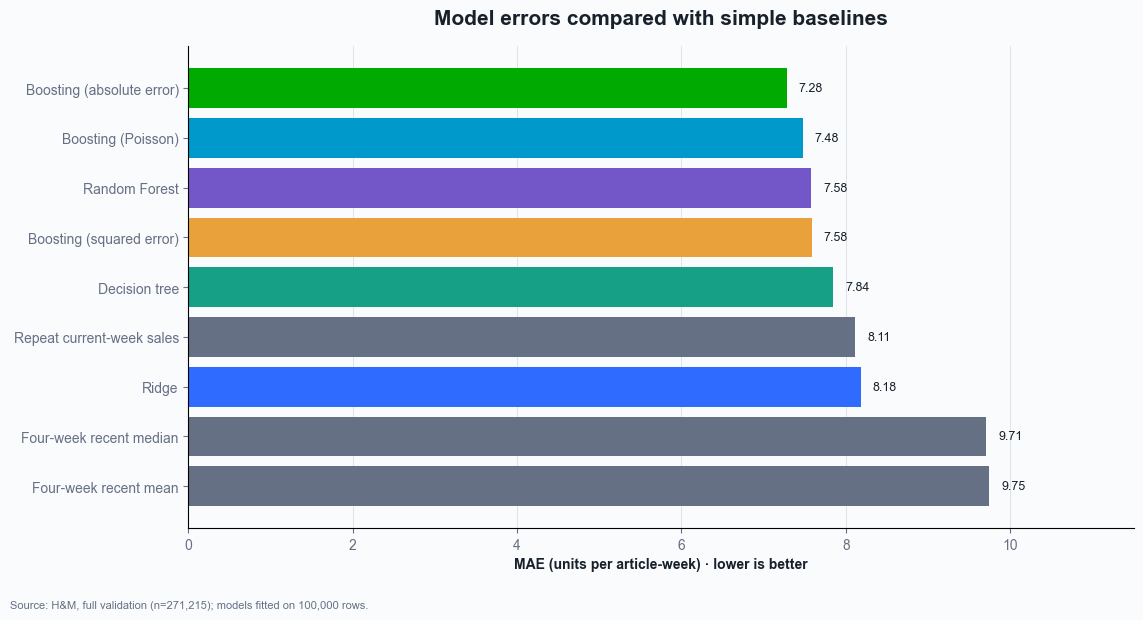

Candidate with the lowest validation MAE: Boosting (absolute error)


In [5]:
from matplotlib import font_manager

available = {font.name for font in font_manager.fontManager.ttflist}
font = next((name for name in ["Arial", "Liberation Sans", "DejaVu Sans"] if name in available), "DejaVu Sans")
plt.rcParams.update({"font.family": font, "figure.facecolor": "#FAFBFC",
                     "axes.facecolor": "#FAFBFC", "text.color": "#17212B",
                     "axes.labelcolor": "#17212B", "xtick.color": "#667085", "ytick.color": "#667085"})

complete = results.loc[results["window"].eq("full")].sort_values("MAE")
names = complete["model_name"].tolist()
errors = complete["MAE"].to_numpy()
fig, ax = plt.subplots(figsize=(11.5, 6.2))
MODEL_COLORS = {
    "Ridge": "#2F6BFF",
    "Decision tree": "#16A085",
    "Random Forest": "#7357C8",
    "Boosting (squared error)": "#E9A23B",
    "Boosting (absolute error)": "#00AA00",
    "Boosting (Poisson)": "#0099CC",
}
colors = [MODEL_COLORS.get(name, "#667085") for name in names]
ax.barh(names[::-1], errors[::-1], color=colors[::-1])
ax.set_xlim(0, max(errors) * 1.18)
ax.set_xlabel("MAE (units per article-week) · lower is better", fontsize=10, fontweight="bold")
ax.set_title("Model errors compared with simple baselines", fontsize=15, fontweight="bold", pad=16)
ax.grid(axis="x", color="#DDE3EA", linewidth=0.7)
ax.set_axisbelow(True)
for spine in ["top", "right"]: ax.spines[spine].set_visible(False)
for y, value in enumerate(errors[::-1]):
    ax.text(value + max(errors) * 0.015, y, f"{value:.2f}", va="center", fontsize=9)
fig.text(0.01, 0.01, f"Source: H&M, full validation (n={len(validation):,}); models fitted on {len(train_sample):,} rows.",
         fontsize=8, color="#667085")
fig.tight_layout(rect=(0, 0.045, 1, 1))
plt.show()

model_only = complete.loc[~complete["model_name"].isin(["Repeat current-week sales", "Four-week recent mean",
                                     "Four-week recent median"])]
chosen = model_only.iloc[0]["model_name"]
print("Candidate with the lowest validation MAE:", chosen)


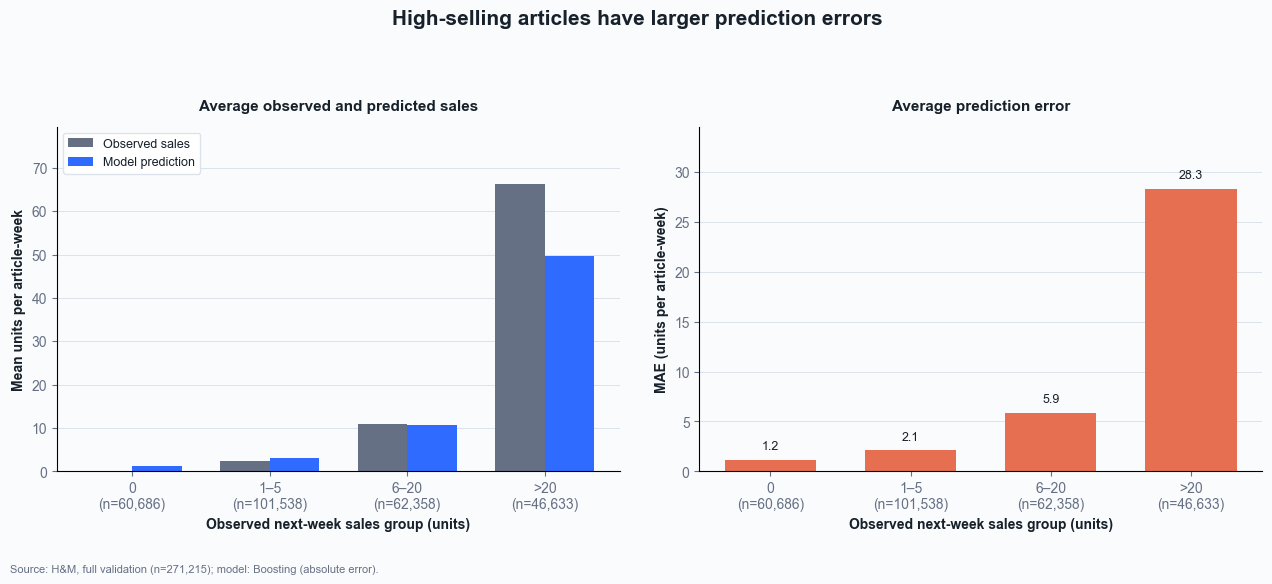


Errors by observed next-week sales group:
                rows     MAE
demand_level                
0              60686   1.188
1–5           101538   2.127
6–20           62358   5.885
>20            46633  28.293

High-sales comparison: 46,633 validation rows with actual sales > 20 units.


Model,Global MAE (units),High-sales MAE (units),Mean prediction − actual (units),High-sales rows underpredicted
Random Forest,7.580,27.549,-10.094,61.0%
Boosting (squared error),7.584,27.574,-10.593,61.9%
Boosting (absolute error),7.280,28.293,-16.479,70.0%
Boosting (Poisson),7.477,27.584,-10.927,62.8%



Errors by product_group_name:
                         rows     MAE
product_group_name                   
Unknown                   582  15.008
Swimwear                14739  14.517
Underwear               18019   9.431
Garment Lower body      58243   7.686
Garment Full body       38300   6.951
Garment Upper body     100331   6.770
Socks & Tights           4872   6.303
Nightwear                3627   6.273
Items                      38   5.172
Shoes                   10622   4.332
Accessories             21588   4.090
Bags                      117   3.583
Stationery                 21   3.412
Garment and Shoe care      40   1.887
Underwear/nightwear        22   0.907
Cosmetic                   37   0.892
Furniture                  15   0.811
Interior textile            2   0.583

Errors by week (first and last):
              rows    MAE
target_week              
2020-03-02   20505  6.218
2020-03-09   20933  4.629
2020-03-16   19361  5.590
2020-05-25   21192  7.001
2020-06-01   21529 

In [6]:
diagnostics = validation[["target_week", "product_group_name", "target_next_week_sales"]].copy()
diagnostics["prediction"] = predictions[chosen]
diagnostics["absolute_error"] = np.abs(diagnostics["target_next_week_sales"] - diagnostics["prediction"])
diagnostics["demand_level"] = pd.cut(diagnostics["target_next_week_sales"],
                                       bins=[-1, 0, 5, 20, np.inf],
                                       labels=["0", "1–5", "6–20", ">20"])

# A simple diagnostic: how close are average predictions in each observed-sales group?
by_demand = diagnostics.groupby("demand_level", observed=True).agg(
    rows=("absolute_error", "size"),
    observed_mean=("target_next_week_sales", "mean"),
    predicted_mean=("prediction", "mean"),
    MAE=("absolute_error", "mean"),
)
labels = by_demand.index.astype(str).tolist()
positions = np.arange(len(labels))
width = 0.36
fig, (ax_actual, ax_error) = plt.subplots(1, 2, figsize=(12.8, 5.8))

ax_actual.bar(positions - width / 2, by_demand["observed_mean"], width,
              color="#667085", label="Observed sales")
ax_actual.bar(positions + width / 2, by_demand["predicted_mean"], width,
              color="#2F6BFF", label="Model prediction")
ax_actual.set_title("Average observed and predicted sales", fontsize=11, fontweight="bold", pad=12)
ax_actual.set_ylabel("Mean units per article-week", fontsize=10, fontweight="bold")
ax_actual.set_ylim(0, max(by_demand["observed_mean"].max(), by_demand["predicted_mean"].max()) * 1.2)
ax_actual.legend(loc="upper left", facecolor="white", edgecolor="#DDE3EA", framealpha=1, fontsize=9)

bars = ax_error.bar(positions, by_demand["MAE"], width=0.65, color="#E76F51")
ax_error.set_title("Average prediction error", fontsize=11, fontweight="bold", pad=12)
ax_error.set_ylabel("MAE (units per article-week)", fontsize=10, fontweight="bold")
ax_error.set_ylim(0, by_demand["MAE"].max() * 1.22)
for bar, value in zip(bars, by_demand["MAE"]):
    ax_error.text(bar.get_x() + bar.get_width() / 2, value + by_demand["MAE"].max() * 0.025,
                  f"{value:.1f}", ha="center", va="bottom", fontsize=9)

for ax in (ax_actual, ax_error):
    ax.set_xticks(positions, [f"{label}\n(n={count:,})" for label, count in zip(labels, by_demand["rows"])])
    ax.set_xlabel("Observed next-week sales group (units)", fontsize=10, fontweight="bold")
    ax.grid(axis="y", color="#DDE3EA", linewidth=0.7)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
fig.suptitle("High-selling articles have larger prediction errors", fontsize=15, fontweight="bold", y=0.98)
fig.text(0.01, 0.01, f"Source: H&M, full validation (n={len(validation):,}); model: {chosen}.",
         fontsize=8, color="#667085")
fig.tight_layout(rect=(0, 0.055, 1, 0.91), w_pad=2.5)
plt.show()

print("\nErrors by observed next-week sales group:")
print(by_demand[["rows", "MAE"]].round(3).to_string())

# This high-sales mask is used only after prediction, never for model fitting.
high_sales_mask = diagnostics["target_next_week_sales"].gt(20).to_numpy()
high_sales_rows = []
for name in ["Random Forest", "Boosting (squared error)", "Boosting (absolute error)", "Boosting (Poisson)"]:
    prediction = predictions[name]
    signed_error = prediction[high_sales_mask] - truth[high_sales_mask]
    high_sales_rows.append({
        "Model": name,
        "Global MAE (units)": mean_absolute_error(truth, prediction),
        "High-sales MAE (units)": np.abs(signed_error).mean(),
        "Mean prediction − actual (units)": signed_error.mean(),
        "High-sales rows underpredicted": (signed_error < 0).mean(),
    })
high_sales_comparison = pd.DataFrame(high_sales_rows)
high_sales_display = high_sales_comparison.copy()
for column in ["Global MAE (units)", "High-sales MAE (units)",
               "Mean prediction − actual (units)"]:
    high_sales_display[column] = high_sales_display[column].map(lambda value: f"{value:.3f}")
high_sales_display["High-sales rows underpredicted"] = high_sales_display[
    "High-sales rows underpredicted"].map(lambda value: f"{value:.1%}")
print(f"\nHigh-sales comparison: {high_sales_mask.sum():,} validation rows with actual sales > 20 units.")
display(HTML(
    '<div style="overflow-x:auto;margin:12px 0 18px;font-family:Arial,sans-serif;">'
    '<div style="font-weight:600;font-size:15px;margin-bottom:9px;">'
    'Global accuracy and high-sales diagnostics</div>'
    + high_sales_display.to_html(index=False, border=0, escape=True, justify="left")
    + '</div>'
))

for group in ["product_group_name", "target_week"]:
    summary = diagnostics.groupby(group, observed=True)["absolute_error"].agg(rows="size", MAE="mean")
    if group == "target_week":
        print("\nErrors by week (first and last):")
        print(pd.concat([summary.head(3), summary.tail(3)]).round(3).to_string())
    else:
        print(f"\nErrors by {group}:")
        print(summary.sort_values("MAE", ascending=False).round(3).to_string())


### What happens for high-selling articles

There are **46,633** validation rows with more than 20 actual next-week sales. Poisson Boosting has MAE **27.584** units in this group. This is better than absolute-error Boosting (**28.293**), but very close to squared-error Boosting (**27.574**) and Random Forest (**27.549**). Poisson predicts below the actual value in **62.8%** of these high-sales rows, with an average signed error of **−10.927** units. Absolute-error Boosting underpredicts **70.0%** of them, with average signed error **−16.479** units.

So Poisson improves high-sales predictions compared with the lowest-global-MAE model, while absolute-error Boosting remains better overall. The figure above still shows **absolute-error Boosting**, because its global MAE is the lowest; the table compares all four models directly. The >20 group is defined after observing outcomes for diagnosis and is never an input to a future prediction.
